<a href="https://colab.research.google.com/github/uavinash15/DataScience-/blob/main/DeepLearning/Neural_Networks/decay_learning_rates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

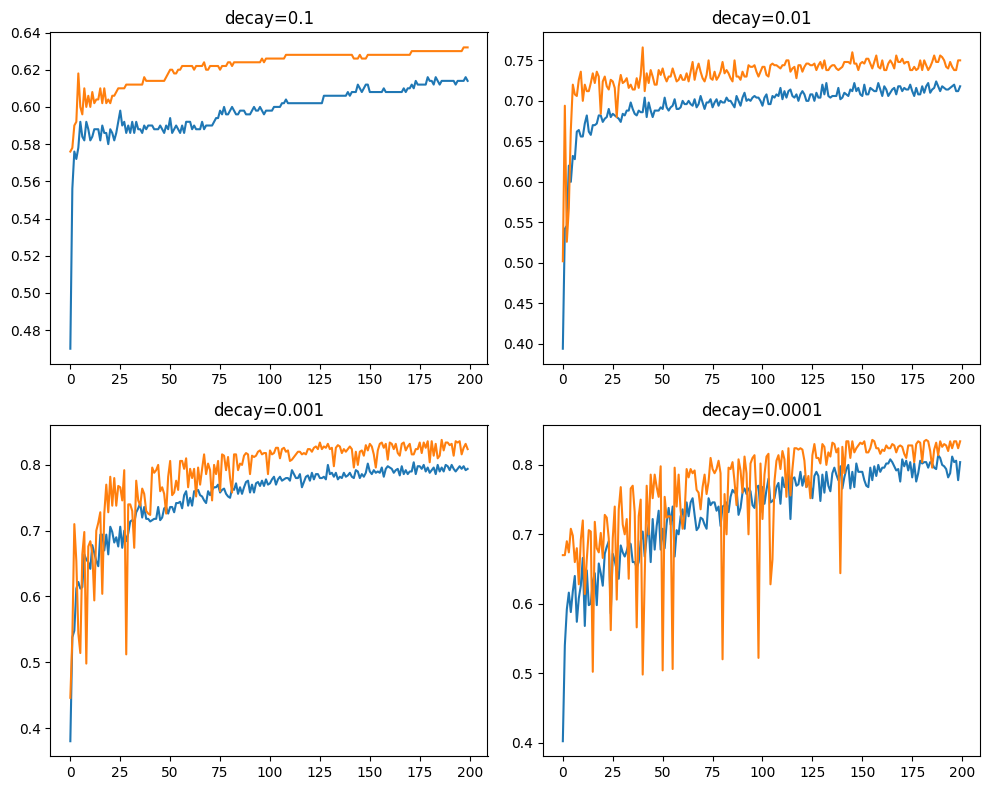

In [1]:
import tensorflow as tf
from sklearn.datasets import make_blobs
from keras.layers import Dense, Input
from keras.models import Sequential
from keras.utils import to_categorical
from matplotlib import pyplot

# prepare train and test dataset
def prepare_data():
        # generate 2d classification dataset
        X, y = make_blobs(n_samples=1000, centers=3, n_features=2, cluster_std=2, random_state=2)
        # one hot encode output variable
        y = to_categorical(y)
        # split into train and test
        n_train = 500
        trainX, testX = X[:n_train, :], X[n_train:, :]
        trainy, testy = y[:n_train], y[n_train:]
        return trainX, trainy, testX, testy

# fit a model and plot learning curve
def fit_model(trainX, trainy, testX, testy, decay):
        # define model
        model = Sequential([
            Input(shape=(2,)),
            Dense(50, activation='relu', kernel_initializer='he_uniform'),
            Dense(3, activation='softmax')
        ])

        # Use Learning Rate Schedule to replace the deprecated decay argument
        # lr = lr_initial / (1 + decay * step)
        lr_schedule = tf.keras.optimizers.schedules.InverseTimeDecay(
            initial_learning_rate=0.01,
            decay_steps=1,
            decay_rate=decay
        )

        opt = tf.keras.optimizers.SGD(learning_rate=lr_schedule)
        model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
        # fit model
        history = model.fit(trainX, trainy, validation_data=(testX, testy), epochs=200, verbose=0)
        # plot learning curves
        pyplot.plot(history.history['accuracy'], label='train')
        pyplot.plot(history.history['val_accuracy'], label='test')
        pyplot.title('decay='+str(decay))

# prepare dataset
trainX, trainy, testX, testy = prepare_data()
# create learning curves for different decay rates
decay_rates = [1E-1, 1E-2, 1E-3, 1E-4]

pyplot.figure(figsize=(10, 8))
for i in range(len(decay_rates)):
        # determine the plot number
        plot_no = 220 + (i+1)
        pyplot.subplot(plot_no)
        # fit model and plot learning curves for a decay rate
        fit_model(trainX, trainy, testX, testy, decay_rates[i])

pyplot.tight_layout()
pyplot.show()